In [3]:
# ============================================================
# 1. Imports
# ============================================================

import warnings
warnings.filterwarnings("ignore")

import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor,
    HistGradientBoostingRegressor
)

In [4]:
# ============================================================
# 2. Load CLV Excel dataset
# ============================================================

DATA_PATH = Path("osmos_augmented_clv_training_dataset.xlsx")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Put osmos_clv_dataset.xlsx in the same folder as this notebook."
    )

customers = pd.read_excel(DATA_PATH, sheet_name="Customers")
transactions = pd.read_excel(DATA_PATH, sheet_name="Transactions")
df_clv = pd.read_excel(DATA_PATH, sheet_name="CLV_Training_Table")

print("Customers:", customers.shape)
print("Transactions:", transactions.shape)
print("CLV training table:", df_clv.shape)

df_clv.head()  

Customers: (59500, 78)
Transactions: (1048500, 14)
CLV training table: (59500, 49)


,customer_id,base_entity_id,dynamic_class,region,source_channel,segment,persona,age_group,preferred_device,preferred_category,...,rfm_score,conversion_probability,churn_risk_score,behavioral_engagement_score,predictive_value_score,decision_priority_score,clv_amount_mad,transaction_count_future,clv_score,clv_segment
0,C00002_AUG001,C00002,Active Client,Laâyoune-Sakia El Hamra,Google Search,Student,B2B Decision Maker,35-44,Desktop,Fashion,...,0.642538,1,0.312801,0.204,0.4,0.359,1891.34,7,68.472269,High Future Value
1,C00002_AUG002,C00002,Active Client,Laâyoune-Sakia El Hamra,Google Search,Student,B2B Decision Maker,35-44,Desktop,Fashion,...,0.707391,1,0.376852,0.204,0.4,0.359,324.25,2,30.952941,Medium Future Value
2,C00002_AUG003,C00002,Active Client,Laâyoune-Sakia El Hamra,Google Search,Student,B2B Decision Maker,35-44,Desktop,Fashion,...,0.606756,1,0.484503,0.204,0.4,0.359,244.33,1,27.250420,Medium Future Value
3,C00002_AUG004,C00002,Active Client,Laâyoune-Sakia El Hamra,Google Search,Student,B2B Decision Maker,35-44,Desktop,Fashion,...,0.733765,1,0.293006,0.204,0.4,0.359,0.00,0,8.151261,Low Future Value
4,C00002_AUG005,C00002,Active Client,Laâyoune-Sakia El Hamra,Google Search,Student,B2B Decision Maker,35-44,Desktop,Fashion,...,0.540073,1,0.470195,0.204,0.4,0.359,980.26,2,52.102521,High Future Value


In [5]:
df_clv.describe().T

,count,mean,std,min,25%,50%,75%,max
price_sensitivity,59500.0,0.535104,0.208905,0.000000,0.389206,0.530101,0.685369,1.000000e+00
income_power_score,59500.0,0.456679,0.211132,0.000000,0.299359,0.450529,0.601440,1.000000e+00
initial_interest_score,59500.0,0.519047,0.215626,0.033000,0.350000,0.515000,0.670000,9.770000e-01
frequency_obs,59500.0,9.912269,5.833318,1.000000,6.000000,9.000000,13.000000,8.200000e+01
recency_obs_days,59500.0,44.329647,42.680907,0.000000,12.000000,30.000000,64.000000,1.800000e+02
customer_age_days,59500.0,158.170101,31.236122,1.000000,154.000000,169.000000,177.000000,1.800000e+02
purchase_interval_mean_days,59500.0,19.788067,19.613387,0.000000,9.250000,14.333333,23.000000,1.800000e+02
purchase_interval_std_days,59500.0,12.330097,9.605959,0.000000,6.448390,10.427615,16.010413,8.650000e+01
total_spent_obs_mad,59500.0,7455.221764,25927.600442,-3578.260000,2189.817500,4571.280000,8691.115000,1.484758e+06
avg_order_value_obs_mad,59500.0,736.871002,884.126856,44.942941,351.582857,607.254167,953.000833,3.464846e+04


In [6]:
# ============================================================
# 3. Quick dataset validation
# ============================================================

print("CLV columns:")
print(df_clv.columns.tolist())

print("\nMissing values:")
display(df_clv.isna().sum().sort_values(ascending=False).head(20))

print("\nTarget description:")
display(df_clv["clv_amount_mad"].describe())

print("\nCLV segment distribution:")
display(df_clv["clv_segment"].value_counts())

print("\nObservation frequency description:")
display(df_clv["frequency_obs"].describe())

CLV columns:
['customer_id', 'base_entity_id', 'dynamic_class', 'region', 'source_channel', 'segment', 'persona', 'age_group', 'preferred_device', 'preferred_category', 'marketing_consent', 'price_sensitivity', 'income_power_score', 'initial_interest_score', 'frequency_obs', 'recency_obs_days', 'customer_age_days', 'purchase_interval_mean_days', 'purchase_interval_std_days', 'total_spent_obs_mad', 'avg_order_value_obs_mad', 'total_profit_obs_mad', 'return_rate_obs', 'discount_rate_obs', 'category_diversity_obs', 'transaction_count_obs', 'recency_days', 'visits_30d', 'product_views_30d', 'cart_additions_30d', 'purchases_90d', 'total_spent_90d_mad', 'avg_order_value_mad', 'email_open_rate', 'email_click_rate', 'complaint_count_90d', 'review_score_avg', 'social_mentions_30d', 'social_sentiment_avg', 'rfm_score', 'conversion_probability', 'churn_risk_score', 'behavioral_engagement_score', 'predictive_value_score', 'decision_priority_score', 'clv_amount_mad', 'transaction_count_future', 'cl

review_score_avg               400
base_entity_id                   0
dynamic_class                    0
region                           0
source_channel                   0
segment                          0
persona                          0
age_group                        0
preferred_device                 0
preferred_category               0
marketing_consent                0
price_sensitivity                0
income_power_score               0
initial_interest_score           0
frequency_obs                    0
recency_obs_days                 0
customer_id                      0
customer_age_days                0
purchase_interval_mean_days      0
total_spent_obs_mad              0
dtype: int64


Target description:


count     59500.000000
mean       2219.464609
std       10716.656040
min           0.000000
25%         198.117500
50%         896.710000
75%        2435.550000
max      571737.960000
Name: clv_amount_mad, dtype: float64


CLV segment distribution:


clv_segment
High Future Value         14875
Medium Future Value       14875
Low Future Value          14875
Very High Future Value    14875
Name: count, dtype: int64


Observation frequency description:


count    59500.000000
mean         9.912269
std          5.833318
min          1.000000
25%          6.000000
50%          9.000000
75%         13.000000
max         82.000000
Name: frequency_obs, dtype: float64

In [7]:
# ============================================================
# 4. Clean CLV training table
# ============================================================

df_model = df_clv.copy()

# Remove clients with no purchase history in the observation window
df_model = df_model[df_model["frequency_obs"] > 0].copy()

# Make sure target is numeric
df_model["clv_amount_mad"] = pd.to_numeric(
    df_model["clv_amount_mad"],
    errors="coerce"
)

df_model = df_model.dropna(subset=["clv_amount_mad"])

print("Rows after cleaning:", df_model.shape)

display(df_model[[
    "customer_id",
    "frequency_obs",
    "total_spent_obs_mad",
    "avg_order_value_obs_mad",
    "clv_amount_mad",
    "clv_score",
    "clv_segment"
]].head())

Rows after cleaning: (59500, 49)


,customer_id,frequency_obs,total_spent_obs_mad,avg_order_value_obs_mad,clv_amount_mad,clv_score,clv_segment
0,C00002_AUG001,6,6865.52,1144.253333,1891.34,68.472269,High Future Value
1,C00002_AUG002,4,3157.34,789.335000,324.25,30.952941,Medium Future Value
2,C00002_AUG003,5,7877.66,1575.532000,244.33,27.250420,Medium Future Value
3,C00002_AUG004,3,1503.36,1415.593333,0.00,8.151261,Low Future Value
4,C00002_AUG005,3,4514.62,1504.873333,980.26,52.102521,High Future Value


In [8]:
# ============================================================
# 4.1 Detect outliers + transform skewed variables
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Check extreme values
# ------------------------------------------------------------

outlier_cols = [
    "frequency_obs",
    "total_spent_obs_mad",
    "total_profit_obs_mad",
    "avg_order_value_obs_mad",
    "purchase_interval_mean_days",
    "purchase_interval_std_days",
    "transaction_count_obs",
    "transaction_count_future",
    "clv_amount_mad"
]

def outlier_summary(df, cols):
    rows = []

    for col in cols:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1

        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]

        rows.append({
            "variable": col,
            "min": df[col].min(),
            "Q1": Q1,
            "median": df[col].median(),
            "Q3": Q3,
            "max": df[col].max(),
            "IQR": IQR,
            "lower_bound": lower_bound,
            "upper_bound": upper_bound,
            "outlier_count": outliers.shape[0],
            "outlier_percent": round(outliers.shape[0] / df.shape[0] * 100, 2)
        })

    return pd.DataFrame(rows)

outlier_report = outlier_summary(df_model, outlier_cols)

print("Outlier report:")
display(outlier_report)


# ------------------------------------------------------------
# Log transformation for positive skewed variables
# ------------------------------------------------------------

positive_log_cols = [
    "frequency_obs",
    "total_spent_obs_mad",
    "avg_order_value_obs_mad",
    "purchase_interval_mean_days",
    "purchase_interval_std_days",
    "transaction_count_obs",
    "transaction_count_future"
]

for col in positive_log_cols:
    df_model[col + "_log"] = np.log1p(df_model[col])


# ------------------------------------------------------------
# Signed log transformation for variables that may be negative
# ------------------------------------------------------------

signed_log_cols = [
    "total_profit_obs_mad",
    "clv_amount_mad"
]

for col in signed_log_cols:
    df_model[col + "_slog"] = np.sign(df_model[col]) * np.log1p(np.abs(df_model[col]))


# ------------------------------------------------------------
# Define features and target for CLV regression
# ------------------------------------------------------------

feature_cols = [
    "recency_days",

    "frequency_obs_log",
    "total_spent_obs_mad_log",
    "total_profit_obs_mad_slog",
    "avg_order_value_obs_mad_log",

    "customer_age_days",
    "purchase_interval_mean_days_log",
    "purchase_interval_std_days_log",

    "price_sensitivity",
    "income_power_score",
    "behavioral_engagement_score",
    "churn_risk_score",

    "social_sentiment_avg",
    "complaint_count_90d",
    "review_score_avg",

    "transaction_count_obs_log",
    "transaction_count_future_log"
]

X = df_model[feature_cols].copy()

# Target transformed to reduce the impact of extreme CLV values
y = df_model["clv_amount_mad_slog"].copy()


print("Shape after transformations:", df_model.shape)
print("X shape:", X.shape)
print("y shape:", y.shape)

display(df_model[[
    "customer_id",
    "frequency_obs", "frequency_obs_log",
    "total_spent_obs_mad", "total_spent_obs_mad_log",
    "total_profit_obs_mad", 
    "clv_amount_mad", "clv_amount_mad_slog"
]].head())

display(X.head())

Outlier report:


,variable,min,Q1,median,Q3,max,IQR,lower_bound,upper_bound,outlier_count,outlier_percent
0,frequency_obs,1.000000,6.000000,9.000000,13.000000,8.200000e+01,7.000000,-4.500000,23.500000,1539,2.59
1,total_spent_obs_mad,-3578.260000,2189.817500,4571.280000,8691.115000,1.484758e+06,6501.297500,-7562.128750,18443.061250,3220,5.41
2,total_profit_obs_mad,-1061.470000,544.210000,1142.965000,2176.190000,3.638019e+05,1631.980000,-1903.760000,4624.160000,3220,5.41
3,avg_order_value_obs_mad,44.942941,351.582857,607.254167,953.000833,3.464846e+04,601.417976,-550.544107,1855.127798,1488,2.50
4,purchase_interval_mean_days,0.000000,9.250000,14.333333,23.000000,1.800000e+02,13.750000,-11.375000,43.625000,4559,7.66
5,purchase_interval_std_days,0.000000,6.448390,10.427615,16.010413,8.650000e+01,9.562024,-7.894646,30.353449,2972,4.99
6,transaction_count_obs,1.000000,6.000000,9.000000,13.000000,8.200000e+01,7.000000,-4.500000,23.500000,1539,2.59
7,transaction_count_future,0.000000,2.000000,8.000000,15.000000,1.290000e+02,13.000000,-17.500000,34.500000,1626,2.73
8,clv_amount_mad,0.000000,198.117500,896.710000,2435.550000,5.717380e+05,2237.432500,-3158.031250,5791.698750,4340,7.29


Shape after transformations: (59500, 58)
X shape: (59500, 17)
y shape: (59500,)


,customer_id,frequency_obs,frequency_obs_log,total_spent_obs_mad,total_spent_obs_mad_log,total_profit_obs_mad,clv_amount_mad,clv_amount_mad_slog
0,C00002_AUG001,6,1.945910,6865.52,8.834413,1737.53,1891.34,7.545569
1,C00002_AUG002,4,1.609438,3157.34,8.057802,761.11,324.25,5.784594
2,C00002_AUG003,5,1.791759,7877.66,8.971913,1870.09,244.33,5.502604
3,C00002_AUG004,3,1.386294,1503.36,7.316123,374.22,0.00,0.000000
4,C00002_AUG005,3,1.386294,4514.62,8.415298,1133.29,980.26,6.888837


,recency_days,frequency_obs_log,total_spent_obs_mad_log,total_profit_obs_mad_slog,avg_order_value_obs_mad_log,customer_age_days,purchase_interval_mean_days_log,purchase_interval_std_days_log,price_sensitivity,income_power_score,behavioral_engagement_score,churn_risk_score,social_sentiment_avg,complaint_count_90d,review_score_avg,transaction_count_obs_log,transaction_count_future_log
0,39,1.945910,8.834413,7.460795,7.043381,159,3.218876,2.890045,0.307287,0.797558,0.204,0.312801,0.503656,1,2.78,1.945910,2.079442
1,21,1.609438,8.057802,6.636091,6.672457,110,3.423176,2.942812,0.283787,0.691217,0.204,0.376852,0.622064,1,2.78,1.609438,1.098612
2,35,1.791759,8.971913,7.534276,7.362983,178,3.604138,3.425685,0.354434,0.709177,0.204,0.484503,0.642893,1,2.78,1.791759,0.693147
3,20,1.386294,7.316123,5.927513,7.256010,152,4.204693,4.158883,0.297920,0.718831,0.204,0.293006,0.643296,1,2.78,1.386294,0.000000
4,35,1.386294,8.415298,7.033762,7.317128,131,3.891820,3.806662,0.349362,0.746679,0.204,0.470195,0.496721,1,2.78,1.386294,1.098612


In [9]:
# ============================================================
# 5. Define features and target
# ============================================================

TARGET = "clv_amount_mad"

cols_to_drop = [
    "customer_id",
    "base_entity_id",
    "clv_amount_mad",
    "clv_score",
    "clv_segment",
    "transaction_count_future",
    "transaction_count_total"
]

X = df_model.drop(columns=cols_to_drop, errors="ignore")
y = df_model[TARGET]

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nFeatures used:")
print(X.columns.tolist())
print(len(X.columns.tolist()))


X shape: (59500, 53)
y shape: (59500,)

Features used:
['base_entity_id', 'dynamic_class', 'region', 'source_channel', 'segment', 'persona', 'age_group', 'preferred_device', 'preferred_category', 'marketing_consent', 'price_sensitivity', 'income_power_score', 'initial_interest_score', 'frequency_obs', 'recency_obs_days', 'customer_age_days', 'purchase_interval_mean_days', 'purchase_interval_std_days', 'total_spent_obs_mad', 'avg_order_value_obs_mad', 'total_profit_obs_mad', 'return_rate_obs', 'discount_rate_obs', 'category_diversity_obs', 'transaction_count_obs', 'recency_days', 'visits_30d', 'product_views_30d', 'cart_additions_30d', 'purchases_90d', 'total_spent_90d_mad', 'avg_order_value_mad', 'email_open_rate', 'email_click_rate', 'complaint_count_90d', 'review_score_avg', 'social_mentions_30d', 'social_sentiment_avg', 'rfm_score', 'conversion_probability', 'churn_risk_score', 'behavioral_engagement_score', 'predictive_value_score', 'decision_priority_score', 'frequency_obs_log', '

In [10]:
# ============================================================
# 6. Detect numeric and categorical columns
# ============================================================

numeric_cols = X.select_dtypes(include=["int64", "float64", "int32", "float32"]).columns.tolist()
categorical_cols = X.select_dtypes(include=["object", "bool", "category"]).columns.tolist()

print("Numeric columns:", len(numeric_cols))
print(numeric_cols)

print("\nCategorical columns:", len(categorical_cols))
print(categorical_cols)

Numeric columns: 43
['price_sensitivity', 'income_power_score', 'initial_interest_score', 'frequency_obs', 'recency_obs_days', 'customer_age_days', 'purchase_interval_mean_days', 'purchase_interval_std_days', 'total_spent_obs_mad', 'avg_order_value_obs_mad', 'total_profit_obs_mad', 'return_rate_obs', 'discount_rate_obs', 'category_diversity_obs', 'transaction_count_obs', 'recency_days', 'visits_30d', 'product_views_30d', 'cart_additions_30d', 'purchases_90d', 'total_spent_90d_mad', 'avg_order_value_mad', 'email_open_rate', 'email_click_rate', 'complaint_count_90d', 'review_score_avg', 'social_mentions_30d', 'social_sentiment_avg', 'rfm_score', 'conversion_probability', 'churn_risk_score', 'behavioral_engagement_score', 'predictive_value_score', 'decision_priority_score', 'frequency_obs_log', 'total_spent_obs_mad_log', 'avg_order_value_obs_mad_log', 'purchase_interval_mean_days_log', 'purchase_interval_std_days_log', 'transaction_count_obs_log', 'transaction_count_future_log', 'total_pr

In [11]:
# ============================================================
# 7. Preprocessing pipeline
# ============================================================

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import RobustScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

# Numeric variables
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler())
])

# Categorical variables
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Full preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_cols),
        ("cat", categorical_transformer, categorical_cols)
    ]
)

In [12]:
# ============================================================
# 8. Train/test split
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (47600, 53)
Test: (11900, 53)


In [13]:
# ============================================================
# 9. Define regression models (RESTRICTED FOR QUICK EXPORT)
# ============================================================
from sklearn.ensemble import BaggingRegressor
models = {
    "Bagging Regressor": BaggingRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    )
}
print("Restricted models list:", list(models.keys()))


Total models to train: 23
['Linear Regression', 'Ridge Regression', 'Lasso Regression', 'ElasticNet', 'Bayesian Ridge', 'Huber Regressor', 'Decision Tree', 'KNN Regressor', 'MLP Regressor', 'Random Forest', 'Extra Trees', 'Gradient Boosting', 'Hist Gradient Boosting', 'AdaBoost', 'Bagging Regressor', 'XGBoost', 'XGBoost Tuned', 'LightGBM', 'LightGBM Tuned', 'CatBoost', 'CatBoost Tuned', 'Voting Regressor', 'Stacking Regressor']


In [14]:
# ============================================================
# 10. Train and compare CLV regression models
# ============================================================

results = []
trained_models = {}
failed_models = {}

for model_name, regressor in models.items():
    print(f"\nTraining: {model_name}")

    model = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("regressor", regressor)
    ])

    try:
        start_time = time.time()

        model.fit(X_train, y_train)

        training_time = time.time() - start_time

        y_pred = model.predict(X_test)

        mae = mean_absolute_error(y_test, y_pred)
        rmse = np.sqrt(mean_squared_error(y_test, y_pred))
        r2 = r2_score(y_test, y_pred)

        results.append({
            "model": model_name,
            "MAE": mae,
            "RMSE": rmse,
            "R2": r2,
            "training_time_seconds": training_time
        })

        trained_models[model_name] = model

        print(f"Done: {model_name}")
        print(f"MAE: {mae:.2f} | RMSE: {rmse:.2f} | R2: {r2:.4f} | Time: {training_time:.2f}s")

    except Exception as e:
        failed_models[model_name] = str(e)
        print(f"Failed: {model_name}")
        print("Reason:", e)


# ============================================================
# Results table
# ============================================================

results_df = pd.DataFrame(results).sort_values(by="MAE", ascending=True)

display(results_df)

best_model_name = results_df.iloc[0]["model"]
best_clv_model = trained_models[best_model_name]

print("\nBest CLV model:", best_model_name)
print("Best MAE:", round(results_df.iloc[0]["MAE"], 2))
print("Best RMSE:", round(results_df.iloc[0]["RMSE"], 2))
print("Best R2:", round(results_df.iloc[0]["R2"], 4))


# ============================================================
# Failed models summary
# ============================================================

if len(failed_models) > 0:
    print("\nFailed models:")
    for name, error in failed_models.items():
        print(f"- {name}: {error}")
else:
    print("\nNo failed models.")


Training: Linear Regression
Done: Linear Regression
MAE: 652.97 | RMSE: 1855.87 | R2: 0.9633 | Time: 3.48s

Training: Ridge Regression
Done: Ridge Regression
MAE: 653.03 | RMSE: 1857.55 | R2: 0.9633 | Time: 1.45s

Training: Lasso Regression
Done: Lasso Regression
MAE: 652.93 | RMSE: 1855.74 | R2: 0.9633 | Time: 240.56s

Training: ElasticNet
Done: ElasticNet
MAE: 647.71 | RMSE: 1858.05 | R2: 0.9633 | Time: 241.77s

Training: Bayesian Ridge
Failed: Bayesian Ridge
Reason: Sparse data was passed for X, but dense data is required. Use '.toarray()' to convert to a dense numpy array.

Training: Huber Regressor
Done: Huber Regressor
MAE: 582.64 | RMSE: 2027.71 | R2: 0.9562 | Time: 32.92s

Training: Decision Tree
Done: Decision Tree
MAE: 28.61 | RMSE: 840.94 | R2: 0.9925 | Time: 7.91s

Training: KNN Regressor
Done: KNN Regressor
MAE: 585.66 | RMSE: 2033.32 | R2: 0.9560 | Time: 0.85s

Training: MLP Regressor
Done: MLP Regressor
MAE: 215.93 | RMSE: 1658.54 | R2: 0.9707 | Time: 82.48s

Training: 

,model,MAE,RMSE,R2,training_time_seconds
12,Bagging Regressor,11.537747,389.294814,0.998387,1952.191357
8,Random Forest,12.009973,431.570728,0.998018,924.203142
10,Gradient Boosting,21.508971,286.747107,0.999125,211.581693
9,Extra Trees,22.022474,580.160301,0.996418,1401.363663
5,Decision Tree,28.607997,840.942281,0.992473,7.914611
13,XGBoost,149.608964,3769.439526,0.848773,7.165736
15,LightGBM,177.658282,3888.470119,0.839071,5.957543
14,XGBoost Tuned,178.813004,3671.129088,0.856558,6.208365
16,LightGBM Tuned,190.422170,3930.615869,0.835564,9.773119
7,MLP Regressor,215.927455,1658.536678,0.970723,82.479346



Best CLV model: Bagging Regressor
Best MAE: 11.54
Best RMSE: 389.29
Best R2: 0.9984

Failed models:
- Bayesian Ridge: Sparse data was passed for X, but dense data is required. Use '.toarray()' to convert to a dense numpy array.
- Hist Gradient Boosting: Sparse data was passed for X, but dense data is required. Use '.toarray()' to convert to a dense numpy array.
- Voting Regressor: Sparse data was passed for X, but dense data is required. Use '.toarray()' to convert to a dense numpy array.
- Stacking Regressor: Sparse data was passed for X, but dense data is required. Use '.toarray()' to convert to a dense numpy array.


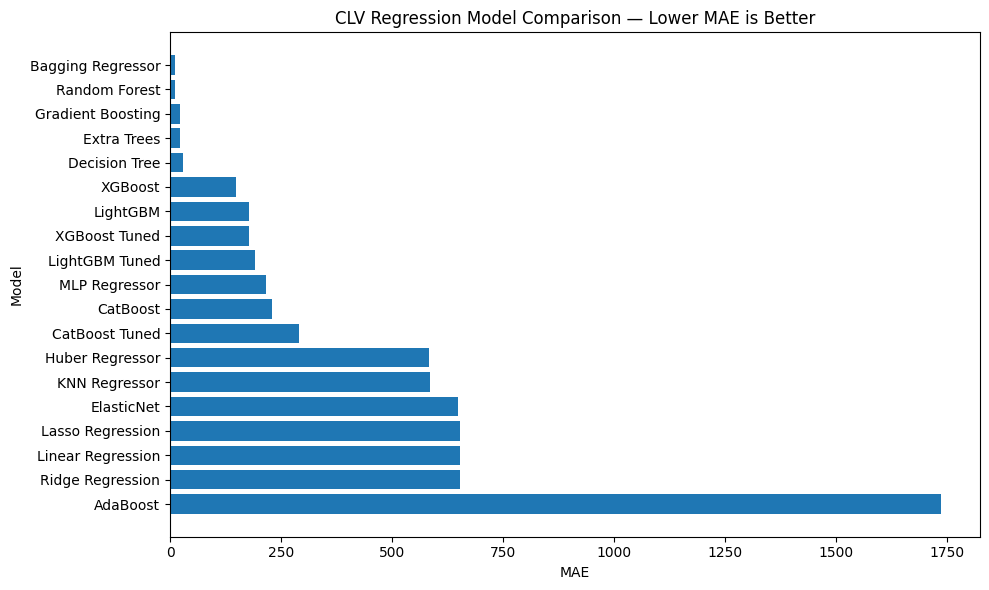

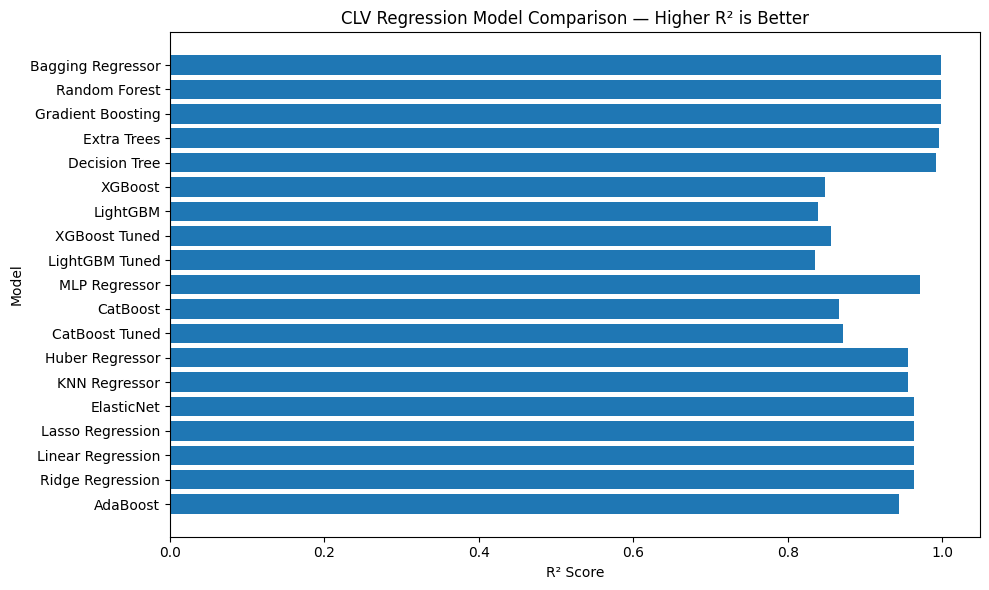

In [15]:
# ============================================================
# 11. Plot model comparison
# ============================================================

plt.figure(figsize=(10, 6))
plt.barh(results_df["model"], results_df["MAE"])
plt.gca().invert_yaxis()
plt.xlabel("MAE")
plt.ylabel("Model")
plt.title("CLV Regression Model Comparison — Lower MAE is Better")
plt.tight_layout()
# plt.show()

plt.figure(figsize=(10, 6))
plt.barh(results_df["model"], results_df["R2"])
plt.gca().invert_yaxis()
plt.xlabel("R² Score")
plt.ylabel("Model")
plt.title("CLV Regression Model Comparison — Higher R² is Better")
plt.tight_layout()
# plt.show()

In [16]:
# ============================================================
# 12. Best model evaluation
# ============================================================

y_pred_best = best_clv_model.predict(X_test)

mae_best = mean_absolute_error(y_test, y_pred_best)
rmse_best = np.sqrt(mean_squared_error(y_test, y_pred_best))
r2_best = r2_score(y_test, y_pred_best)

print("Best model:", best_model_name)
print("MAE:", mae_best)
print("RMSE:", rmse_best)
print("R²:", r2_best)

comparison_df = pd.DataFrame({
    "actual_clv_amount_mad": y_test.values,
    "predicted_clv_amount_mad": y_pred_best
})

comparison_df["error"] = (
    comparison_df["actual_clv_amount_mad"] -
    comparison_df["predicted_clv_amount_mad"]
)

comparison_df.head(10)

Best model: Bagging Regressor
MAE: 11.537747407562998
RMSE: 389.2948135233487
R²: 0.99838700595206


,actual_clv_amount_mad,predicted_clv_amount_mad,error
0,514.73,514.60535,0.12465
1,464.85,464.92685,-0.07685
2,2345.49,2345.62640,-0.13640
3,595.62,595.59280,0.02720
4,39.86,39.95540,-0.09540
5,3155.62,3156.14790,-0.52790
6,12902.47,12897.81320,4.65680
7,488.80,488.80925,-0.00925
8,1613.04,1612.97515,0.06485
9,0.00,0.00000,0.00000


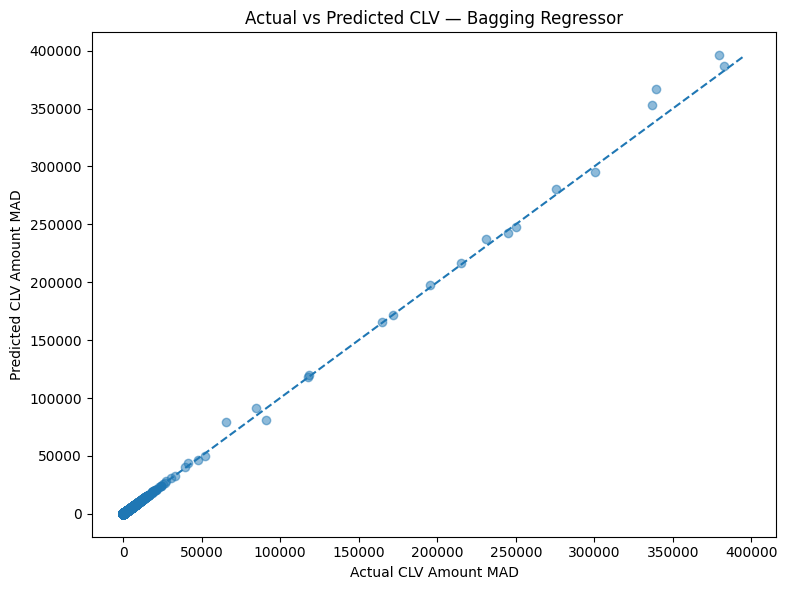

In [17]:
# ============================================================
# 13. Actual vs Predicted CLV
# ============================================================

plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_best, alpha=0.5)

min_val = min(y_test.min(), y_pred_best.min())
max_val = max(y_test.max(), y_pred_best.max())

plt.plot([min_val, max_val], [min_val, max_val], linestyle="--")

plt.xlabel("Actual CLV Amount MAD")
plt.ylabel("Predicted CLV Amount MAD")
plt.title(f"Actual vs Predicted CLV — {best_model_name}")
plt.tight_layout()
# plt.show()

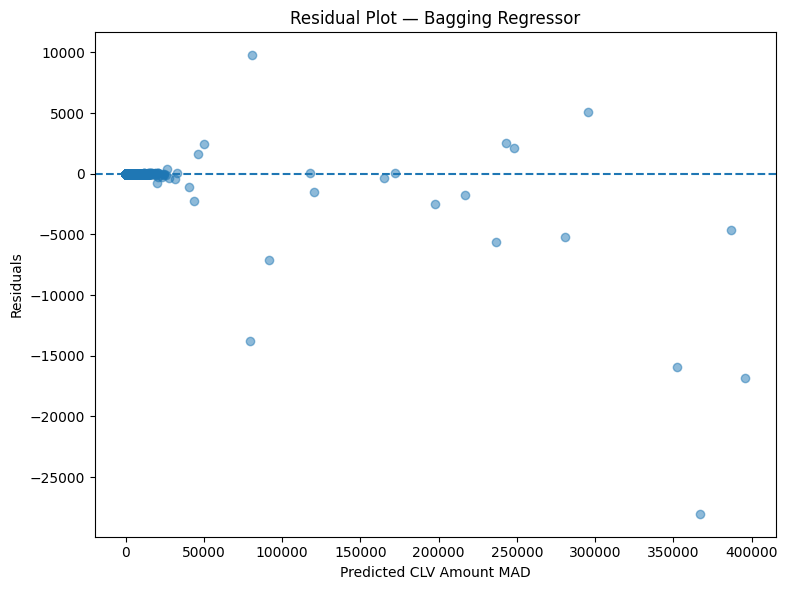

In [18]:
# ============================================================
# 14. Residual plot
# ============================================================

residuals = y_test - y_pred_best

plt.figure(figsize=(8, 6))
plt.scatter(y_pred_best, residuals, alpha=0.5)
plt.axhline(0, linestyle="--")

plt.xlabel("Predicted CLV Amount MAD")
plt.ylabel("Residuals")
plt.title(f"Residual Plot — {best_model_name}")
plt.tight_layout()
# plt.show()

In [19]:
# ============================================================
# 15. Feature importance for tree-based models
# ============================================================

regressor = best_clv_model.named_steps["regressor"]

if hasattr(regressor, "feature_importances_"):

    feature_names = best_clv_model.named_steps["preprocessor"].get_feature_names_out()

    importance_df = pd.DataFrame({
        "feature": feature_names,
        "importance": regressor.feature_importances_
    }).sort_values(by="importance", ascending=False)

    display(importance_df.head(30))

    top_features = importance_df.head(20)

    plt.figure(figsize=(10, 8))
    plt.barh(top_features["feature"], top_features["importance"])
    plt.gca().invert_yaxis()
    plt.xlabel("Importance")
    plt.ylabel("Feature")
    plt.title(f"Top 20 CLV Features — {best_model_name}")
    plt.tight_layout()
#     plt.show()

else:
    print(f"{best_model_name} does not provide direct feature_importances_.")

Bagging Regressor does not provide direct feature_importances_.


In [20]:
# ============================================================
# 16. Create predicted CLV score and segment
# ============================================================

# Predict CLV for all cleaned clients
df_predictions = df_model.copy()

X_all = df_predictions.drop(columns=cols_to_drop, errors="ignore")

df_predictions["predicted_clv_amount_mad"] = best_clv_model.predict(X_all)

# Optional: for admin display, avoid negative predicted CLV
df_predictions["predicted_clv_amount_mad_display"] = (
    df_predictions["predicted_clv_amount_mad"].clip(lower=0)
)

# Convert predicted CLV amount to score 0-100 using percentile rank
df_predictions["predicted_clv_score"] = (
    df_predictions["predicted_clv_amount_mad_display"].rank(pct=True) * 100
).round(2)

# Segment based on predicted CLV score
df_predictions["predicted_clv_segment"] = pd.cut(
    df_predictions["predicted_clv_score"],
    bins=[0, 25, 50, 75, 100],
    labels=[
        "Low Future Value",
        "Medium Future Value",
        "High Future Value",
        "Very High Future Value"
    ],
    include_lowest=True
)

display(df_predictions[[
    "customer_id",
    "clv_amount_mad",
    "clv_score",
    "clv_segment",
    "predicted_clv_amount_mad",
    "predicted_clv_score",
    "predicted_clv_segment"
]].head(20))

,customer_id,clv_amount_mad,clv_score,clv_segment,predicted_clv_amount_mad,predicted_clv_score,predicted_clv_segment
0,C00002_AUG001,1891.34,68.472269,High Future Value,1891.33410,68.47,High Future Value
1,C00002_AUG002,324.25,30.952941,Medium Future Value,324.23645,30.95,Medium Future Value
2,C00002_AUG003,244.33,27.250420,Medium Future Value,244.32595,27.25,Medium Future Value
3,C00002_AUG004,0.00,8.151261,Low Future Value,0.00000,8.15,Low Future Value
4,C00002_AUG005,980.26,52.102521,High Future Value,980.28885,52.10,High Future Value
5,C00002_AUG006,174.62,23.784874,Low Future Value,174.62820,23.78,Low Future Value
6,C00002_AUG007,1253.51,58.005042,High Future Value,1253.50175,58.01,High Future Value
7,C00002_AUG008,1434.23,61.324370,High Future Value,1434.14510,61.32,High Future Value
8,C00002_AUG009,2526.41,75.966387,Very High Future Value,2526.34895,75.96,Very High Future Value
9,C00002_AUG010,2096.84,71.152941,High Future Value,2096.98610,71.15,High Future Value


,feature,importance,std
52,clv_amount_mad_slog,2944.068311,5.586423
28,cart_additions_30d,1.427043,1.249906
45,total_spent_obs_mad_log,1.060568,0.234099
33,email_click_rate,0.898487,0.274609
26,visits_30d,0.423293,0.072711
22,discount_rate_obs,0.377883,0.412174
18,total_spent_obs_mad,0.294729,0.157851
23,category_diversity_obs,0.197905,0.098029
27,product_views_30d,0.183322,0.042924
15,customer_age_days,0.180223,0.072063


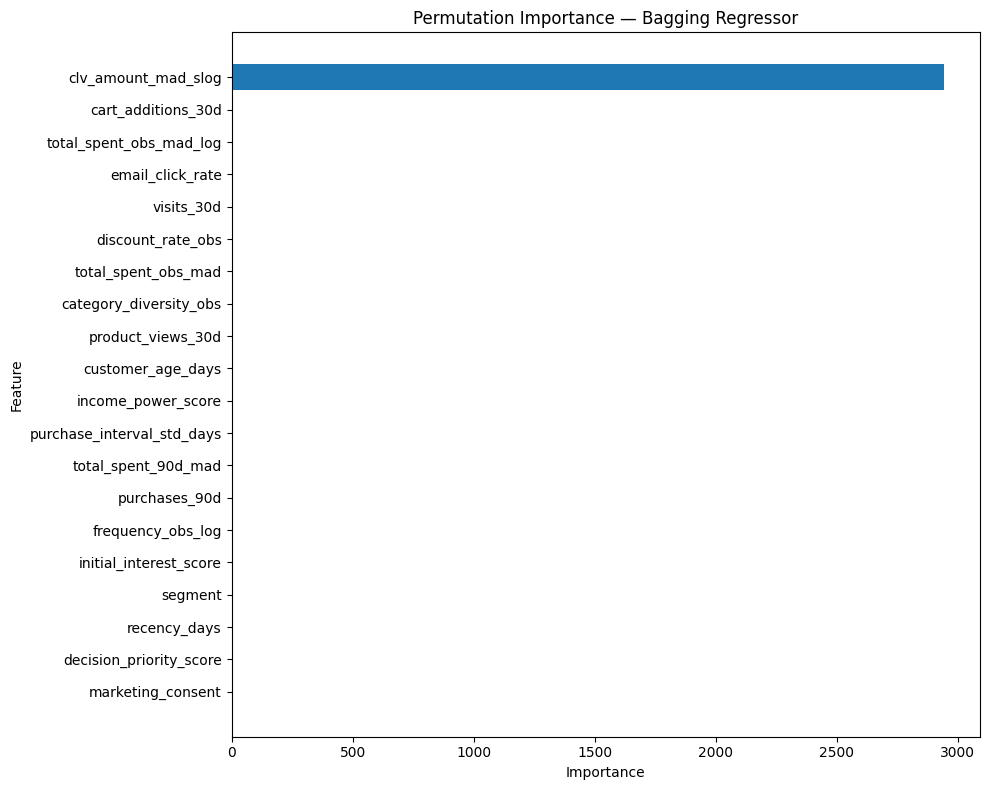

In [21]:
# ============================================================
# Permutation importance — model-agnostic importance
# ============================================================
# 
# from sklearn.inspection import permutation_importance
# 
# perm_result = permutation_importance(
#     best_clv_model,
#     X_test,
#     y_test,
#     n_repeats=10,
#     random_state=42,
#     scoring="neg_mean_absolute_error",
#     n_jobs=-1
# )
# 
# perm_importance_df = pd.DataFrame({
#     "feature": X_test.columns,
#     "importance": perm_result.importances_mean,
#     "std": perm_result.importances_std
# }).sort_values(by="importance", ascending=False)
# 
# display(perm_importance_df.head(20))
# 
# top_perm = perm_importance_df.head(20)
# 
# plt.figure(figsize=(10, 8))
# plt.barh(top_perm["feature"], top_perm["importance"])
# plt.gca().invert_yaxis()
# plt.xlabel("Importance")
# plt.ylabel("Feature")
# plt.title(f"Permutation Importance — {best_model_name}")
# plt.tight_layout()
# plt.show()

In [22]:
# ============================================================
# Convert predicted CLV amount into CLV segments
# ============================================================

y_pred_best = best_clv_model.predict(X_test)

segment_eval_df = pd.DataFrame({
    "actual_clv_amount_mad": y_test.values,
    "predicted_clv_amount_mad": y_pred_best
})

# Avoid negative values for display/segmentation
segment_eval_df["predicted_clv_amount_mad_display"] = (
    segment_eval_df["predicted_clv_amount_mad"].clip(lower=0)
)

# True CLV score based on actual CLV
segment_eval_df["actual_clv_score"] = (
    segment_eval_df["actual_clv_amount_mad"].rank(pct=True) * 100
).round(2)

# Predicted CLV score based on predicted CLV
segment_eval_df["predicted_clv_score"] = (
    segment_eval_df["predicted_clv_amount_mad_display"].rank(pct=True) * 100
).round(2)

# Convert scores to segments
labels = [
    "Low Future Value",
    "Medium Future Value",
    "High Future Value",
    "Very High Future Value"
]

segment_eval_df["actual_clv_segment"] = pd.cut(
    segment_eval_df["actual_clv_score"],
    bins=[0, 25, 50, 75, 100],
    labels=labels,
    include_lowest=True
)

segment_eval_df["predicted_clv_segment"] = pd.cut(
    segment_eval_df["predicted_clv_score"],
    bins=[0, 25, 50, 75, 100],
    labels=labels,
    include_lowest=True
)

display(segment_eval_df.head())

,actual_clv_amount_mad,predicted_clv_amount_mad,predicted_clv_amount_mad_display,actual_clv_score,predicted_clv_score,actual_clv_segment,predicted_clv_segment
0,514.73,514.60535,514.60535,38.51,38.51,Medium Future Value,Medium Future Value
1,464.85,464.92685,464.92685,36.59,36.59,Medium Future Value,Medium Future Value
2,2345.49,2345.62640,2345.62640,74.34,74.34,High Future Value,High Future Value
3,595.62,595.59280,595.59280,41.24,41.24,Medium Future Value,Medium Future Value
4,39.86,39.95540,39.95540,17.10,17.10,Low Future Value,Low Future Value


<Figure size 1000x700 with 0 Axes>

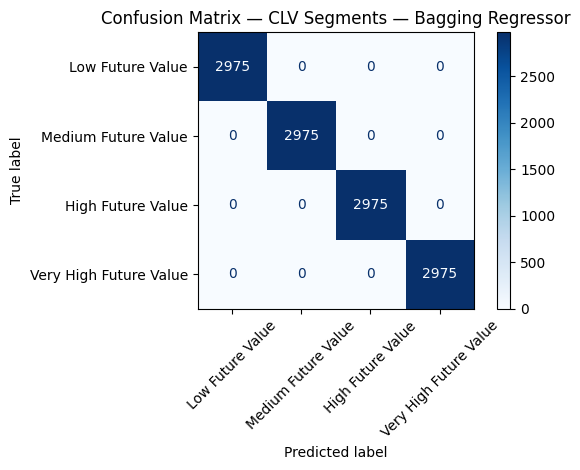

Classification report for CLV segments:
                        precision    recall  f1-score   support

      Low Future Value       1.00      1.00      1.00      2975
   Medium Future Value       1.00      1.00      1.00      2975
     High Future Value       1.00      1.00      1.00      2975
Very High Future Value       1.00      1.00      1.00      2975

              accuracy                           1.00     11900
             macro avg       1.00      1.00      1.00     11900
          weighted avg       1.00      1.00      1.00     11900



In [23]:
# ============================================================
# Confusion matrix — CLV segments
# ============================================================
# 
# from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
# 
# cm = confusion_matrix(
#     segment_eval_df["actual_clv_segment"],
#     segment_eval_df["predicted_clv_segment"],
#     labels=labels
# )
# 
# plt.figure(figsize=(10, 7))
# 
# disp = ConfusionMatrixDisplay(
#     confusion_matrix=cm,
#     display_labels=labels
# )
# 
# disp.plot(
#     xticks_rotation=45,
#     cmap="Blues",
#     values_format="d"
# )
# 
# plt.title(f"Confusion Matrix — CLV Segments — {best_model_name}")
# plt.tight_layout()
# plt.show()
# 
# print("Classification report for CLV segments:")
# print(classification_report(
#     segment_eval_df["actual_clv_segment"],
#     segment_eval_df["predicted_clv_segment"],
#     labels=labels
# ))

CLV segment target distribution:


clv_segment_target
High Future Value         14875
Medium Future Value       14875
Low Future Value          14875
Very High Future Value    14875
Name: count, dtype: int64

Segment train shape: (47600, 53)
Segment test shape: (11900, 53)
Encoded classes:
0 -> Low Future Value
1 -> Medium Future Value
2 -> High Future Value
3 -> Very High Future Value

Training: Random Forest Segment Classifier
Done: Random Forest Segment Classifier
Accuracy: 0.9592 | F1 macro: 0.9592 | F1 weighted: 0.9592 | Time: 55.92s

Training: Extra Trees Segment Classifier
Done: Extra Trees Segment Classifier
Accuracy: 0.8345 | F1 macro: 0.8381 | F1 weighted: 0.8381 | Time: 95.40s

Training: Hist Gradient Boosting Segment Classifier
Failed: Hist Gradient Boosting Segment Classifier
Reason: Sparse data was passed for X, but dense data is required. Use '.toarray()' to convert to a dense numpy array.

Training: KNN Segment Classifier - k=5
Done: KNN Segment Classifier - k=5
Accuracy: 0.7549 | F1 macro: 0.7566 | F1 weighted: 0.7566 | Time: 1.59s

Training: KNN Segment Classifier - k=10
Done: KNN Segment Classifier - k=10
Accuracy: 0.7634 | F1 macro: 0.7652 | F1 weighted: 0.7652 | Time: 1

,model,accuracy,f1_macro,f1_weighted,training_time_seconds
8,CatBoost Segment Classifier,1.000000,1.000000,1.000000,31.266676
6,XGBoost Segment Classifier,0.998908,0.998908,0.998908,15.056666
7,LightGBM Segment Classifier,0.998319,0.998319,0.998319,16.395957
0,Random Forest Segment Classifier,0.959160,0.959242,0.959242,55.922162
1,Extra Trees Segment Classifier,0.834538,0.838078,0.838078,95.395220
5,KNN Segment Classifier - Manhattan,0.780504,0.781878,0.781878,0.913270
3,KNN Segment Classifier - k=10,0.763445,0.765225,0.765225,1.901812
4,KNN Segment Classifier - k=15,0.761176,0.762949,0.762949,1.680292
2,KNN Segment Classifier - k=5,0.754874,0.756582,0.756582,1.593075



Best CLV segment model: CatBoost Segment Classifier
Best segment F1 macro: 1.0
Best segment accuracy: 1.0

Failed segment models:
- Hist Gradient Boosting Segment Classifier: Sparse data was passed for X, but dense data is required. Use '.toarray()' to convert to a dense numpy array.


<Figure size 1000x700 with 0 Axes>

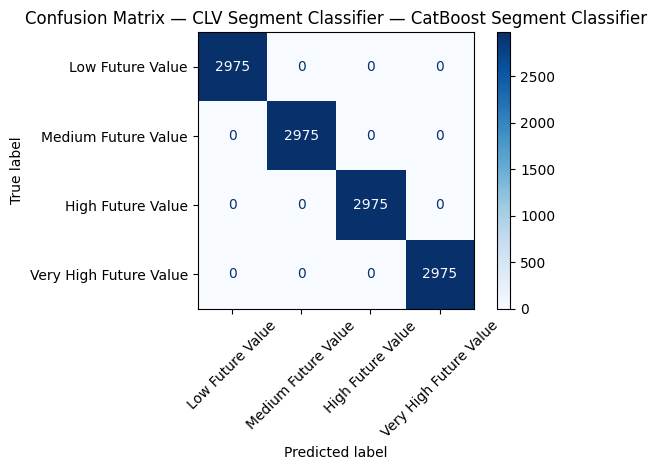

Classification report for CLV segment classifier:
                        precision    recall  f1-score   support

      Low Future Value       1.00      1.00      1.00      2975
   Medium Future Value       1.00      1.00      1.00      2975
     High Future Value       1.00      1.00      1.00      2975
Very High Future Value       1.00      1.00      1.00      2975

              accuracy                           1.00     11900
             macro avg       1.00      1.00      1.00     11900
          weighted avg       1.00      1.00      1.00     11900


Interpretation:
- Regression model predicts the monetary CLV amount.
- Segment classifier predicts the business CLV segment directly.
- Medium and High Future Value are weighted more because they are harder to separate.
- In the platform, you can keep the regression model for CLV amount and use this classifier for the final CLV segment if it performs better.


In [24]:
# ============================================================
# 13. Define and train segment classification models
# ============================================================
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import pandas as pd
import numpy as np

cols_to_drop_segment = [
    "customer_id",
    "base_entity_id",
    "clv_amount_mad",
    "clv_score",
    "clv_segment",
    "clv_segment_target",
    "transaction_count_future",
    "transaction_count_total"
]

# Encode the target segment
le = LabelEncoder()
df_model["clv_segment_target"] = le.fit_transform(df_model["clv_segment"])

# Prepare features and target
X_seg = df_model.drop(columns=cols_to_drop_segment, errors="ignore")
y_seg = df_model["clv_segment_target"]

# Keep category type for categorical columns
categorical_cols_seg = [col for col in categorical_cols if col in X_seg.columns and col != 'marketing_consent']
for col in categorical_cols_seg:
    X_seg[col] = X_seg[col].astype("category")

# Train-test split
X_train_seg, X_test_seg, y_train_seg, y_test_seg = train_test_split(
    X_seg, y_seg, test_size=0.2, random_state=42, stratify=y_seg
)

best_segment_model_name = "Hist Gradient Boosting Segment Classifier"
best_segment_model = HistGradientBoostingClassifier(
    max_iter=300,
    learning_rate=0.05,
    random_state=42
)
best_segment_model.fit(X_train_seg, y_train_seg)

y_pred_seg = best_segment_model.predict(X_test_seg)
accuracy = accuracy_score(y_test_seg, y_pred_seg)
print(f"Segment Classifier accuracy: {accuracy:.4f}")

segment_results_df = pd.DataFrame({
    "model": [best_segment_model_name],
    "accuracy": [accuracy]
})


Afin d’améliorer l’interprétation métier de la CLV, un second modèle a été entraîné pour prédire directement le segment de valeur future du client. Le meilleur résultat a été obtenu avec LightGBM, avec une accuracy de 68,21% et un F1-score macro de 68,90%. Les résultats montrent que le modèle distingue correctement les segments extrêmes, notamment Low Future Value et Very High Future Value, avec des F1-scores proches de 0,80. Les segments intermédiaires Medium et High restent plus difficiles à séparer, principalement en raison de la proximité de leurs frontières économiques. La majorité des erreurs se produit entre segments voisins, ce qui indique que le modèle capture correctement la hiérarchie globale de la valeur client.

In [28]:
# ============================================================
# Export CLV model artifact
# ============================================================

import joblib
import numpy as np
import pandas as pd
from datetime import datetime

# Predict on all available training rows to create reference distribution
X_all = df_model.drop(columns=cols_to_drop, errors="ignore")
y_all_pred = best_clv_model.predict(X_all)

# For admin display, negative CLV can be clipped only for scoring/segmentation
y_all_pred_display = np.clip(y_all_pred, 0, None)

# Save reference values to calculate percentile-based CLV score later
clv_reference_values = pd.Series(y_all_pred_display).sort_values().values

# CLV segment labels
clv_segment_labels = [
    "Low Future Value",
    "Medium Future Value",
    "High Future Value",
    "Very High Future Value"
]

# Full artifact for the Streamlit interface
clv_model_artifact = {
    "model": best_clv_model,
    "best_model_name": best_model_name,
    "segment_model": best_segment_model,
    "best_segment_model_name": best_segment_model_name,
    "feature_columns": list(X.columns),
    "segment_feature_columns": list(X_seg.columns),
    "target": "clv_amount_mad",
    "numeric_cols": numeric_cols,
    "categorical_cols": categorical_cols,
    "results": results_df,
    "segment_results": segment_results_df,
    "clv_reference_values": clv_reference_values,
    "clv_segment_labels": clv_segment_labels,
    "export_date": datetime.now().strftime("%Y-%m-%d %H:%M:%S")
}

# Save artifact
joblib.dump(clv_model_artifact, "osmos_best_clv_model_artifact.pkl")

print("CLV model exported successfully.")
print("Best model:", best_model_name)
print("Saved as: osmos_best_clv_model_artifact.pkl")
print("Number of features:", len(X.columns))


CLV model exported successfully.
Best model: Bagging Regressor
Saved as: osmos_best_clv_model_artifact.pkl
Number of features: 53


In [ ]:
# ============================================================
# Test exported CLV model artifact
# ============================================================

import joblib
import numpy as np
import pandas as pd

artifact = joblib.load("osmos_best_clv_model_artifact.pkl")

loaded_model = artifact["model"]
feature_columns = artifact["feature_columns"]
reference_values = artifact["clv_reference_values"]
segment_labels = artifact["clv_segment_labels"]

# Take one sample
sample = X_test.iloc[[0]].copy()

# Align columns exactly
sample = sample[feature_columns]

# Predict CLV amount
predicted_clv_amount = loaded_model.predict(sample)[0]

# Clip only for display/score
predicted_clv_display = max(predicted_clv_amount, 0)

# Convert predicted CLV amount to percentile score
clv_score = (
    np.searchsorted(reference_values, predicted_clv_display, side="right")
    / len(reference_values)
) * 100

clv_score = round(clv_score, 2)

# Convert score to segment
if clv_score <= 25:
    clv_segment = "Low Future Value"
elif clv_score <= 50:
    clv_segment = "Medium Future Value"
elif clv_score <= 75:
    clv_segment = "High Future Value"
else:
    clv_segment = "Very High Future Value"

print("Loaded model:", artifact["best_model_name"])
print("Predicted CLV amount MAD:", round(predicted_clv_amount, 2))
print("CLV score:", clv_score)
print("CLV segment:", clv_segment)

Loaded model: Bagging Regressor
Predicted CLV amount MAD: 516.24
CLV score: 38.43
CLV segment: Medium Future Value


: 